In [ ]:
import numpy as np
from tqdm.auto import trange
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedShuffleSplit

from utils import TrialAveragePCA, plot_accuracy

# Generate random data

In [2]:
n_trials = 50  # number of trials for each class
n_neurons = 100  # number of neurons
y_unique = np.arange(4)  # unique classes
n_stim = len(y_unique)

# fix random seed for reproducibility
seed: int = 42
np.random.seed(seed)

# generate random data
# X is the neural data, y is the class label
X = np.random.randn(n_trials * n_stim, n_neurons)
y = np.repeat(y_unique, n_trials)

# Example decoding pipelines

## without data leakage

Here data is first split into training and test sets.
Parameters to preprocess the data are derived purely from the training set.

In [3]:
# stratified is used to ensure the same class distribution in each split
skf = StratifiedShuffleSplit(n_splits=200, random_state=seed)
pca = TrialAveragePCA(n_components=3, random_state=seed)
lda = LDA()

score_all = []
for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    X_train_new = pca.fit_transform(X_train, y_train)
    X_test_new = pca.transform(X_test)

    lda.fit(X_train_new, y_train)
    score_tmp = lda.score(X_test_new, y_test)

    score_all.append(score_tmp)

In [4]:
# alternatively we can use `cross_val_score` and `make_pipeline`
# to avoid the for loop
model = make_pipeline(pca, lda)
scores1 = cross_val_score(model, X, y, cv=skf)

## with data leakage

Here the entire dataset is used during the preprocessing step.

In [5]:
X_processed = pca.fit_transform(X, y)

score_all = []
for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train, X_test = X_processed[train_index], X_processed[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lda.fit(X_train, y_train)
    score_tmp = lda.score(X_test, y_test)

    score_all.append(score_tmp)

In [6]:
# alternatively we can use `cross_val_score` to avoid the for loop
scores2 = cross_val_score(lda, X_processed, y, cv=skf)

## shuffle control

Here we perform shuffle control on a decoding pipeline without data leakage.
Shuffling is done at the start of the pipeline before any preprocessing.

In [7]:
# cast y to pandas series for shuffling
y_series = pd.Series(y)
n_shuffle: int = 100

score_shuffle = []
for i in trange(n_shuffle, desc="shuffle control"):
    scores = cross_val_score(
        model, X, y_series.sample(frac=1, random_state=seed + i), cv=skf
    )
    score_shuffle.append(scores.mean())

shuffle control:   0%|          | 0/100 [00:00<?, ?it/s]

## plot

(<Figure size 250x200 with 1 Axes>, <Axes: ylabel='Accuracy'>)

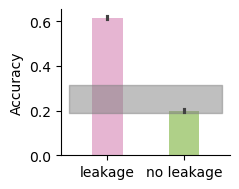

In [8]:
cmap = sns.color_palette("PiYG")
palette = {"leakage": cmap[1], "no leakage": cmap[-2]}

# plot the results
df_tmp1 = pd.DataFrame({"accuracy": scores1, "method": "no leakage"})
df_tmp2 = pd.DataFrame({"accuracy": scores2, "method": "leakage"})
df_tmp = pd.concat([df_tmp1, df_tmp2])

plot_accuracy(df_tmp, score_shuffle, palette)

# Shuffle control

Below we show the effect of shuffling on the class labels at different levels of the decoding pipeline.

- **shuffle control 2**:
Class labels were shuffled just before the decoder.
Although data leakage exists in this pipeline, the confidence interval from shuffle controls are still at chance level.
- **shuffle control 3**:
Class labels were shuffled at the start of the pipeline.
The confidence interval from shuffle controls can be well-above chance level, if data leakage exists in the pipeline.

## Shuffle control 2

Here shuffle control is performed just before decoding.
In this case the pipeline may involve data leakage,
however the confidence interval from the shuffle control cannot be used to determine if data leakage occurred.

In [9]:
# first we preprocess the neural data
X_processed = pca.fit_transform(X, y)

score_shuffle = []
for i in trange(n_shuffle, desc="shuffle control"):
    scores = cross_val_score(
        lda, X_processed, y_series.sample(frac=1, random_state=seed + i), cv=skf
    )
    score_shuffle.append(scores.mean())

shuffle control:   0%|          | 0/100 [00:00<?, ?it/s]

(<Figure size 250x200 with 1 Axes>, <Axes: ylabel='Accuracy'>)

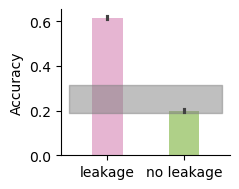

In [10]:
plot_accuracy(df_tmp, score_shuffle, palette)

## Shuffle control 3

Here we perform shuffle control on a decoding pipeline **with** data leakage.
Shuffling is done at the start of the pipeline before any preprocessing.

We can see the confidence interval from shuffle control is well-above the chance level,
indicating there is data leakage in the decoding pipeline.

In [11]:
score_shuffle = []
for i in trange(n_shuffle, desc="shuffle control"):
    # shuffle the class labels
    y_tmp = y_series.sample(frac=1, random_state=seed + i)
    # fit the PCA and LDA using the shuffled class labels
    X_processed = pca.fit_transform(X, y_tmp)
    scores = cross_val_score(lda, X_processed, y_tmp, cv=skf)

    score_shuffle.append(scores.mean())

shuffle control:   0%|          | 0/100 [00:00<?, ?it/s]

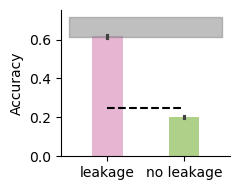

In [12]:
fig, ax = plot_accuracy(df_tmp, score_shuffle, palette)
ax.hlines(1 / n_stim, 0, 1, linestyle="--", color="k")